# FraudGuard — Credit Card Fraud Detection

A compact machine learning project for detecting fraudulent credit card transactions.

## Objectives
- Explore transaction data and class imbalance.
- Train and compare two classification models.
- Evaluate fraud detection using Precision, Recall, F1-score, and Average Precision.
- Analyze false positives and missed fraudulent transactions.

## Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
dataset = fetch_openml(data_id=1597, as_frame=True)

df = dataset.data.copy()
df["Class"] = dataset.target.astype(int).to_numpy()

print("Original dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Class"].value_counts())

Original dataset shape: (284807, 30)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [5]:
fraud = df[df["Class"] == 1]
legitimate = df[df["Class"] == 0]

fraud_sample = fraud.sample(
    n=min(150, len(fraud)),
    random_state=RANDOM_STATE
)

legitimate_sample = legitimate.sample(
    n=min(15000, len(legitimate)),
    random_state=RANDOM_STATE
)

mini_df = pd.concat(
    [fraud_sample, legitimate_sample],
    ignore_index=True
).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Mini dataset shape:", mini_df.shape)
print("\nClass distribution:")
print(mini_df["Class"].value_counts())

display(mini_df.head())

Mini dataset shape: (15150, 30)

Class distribution:
Class
0    15000
1      150
Name: count, dtype: int64


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.193558,1.603153,1.460880,2.892423,0.539453,0.949329,-0.152326,0.533829,0.162927,0.315576,...,0.178522,0.492015,-0.150269,0.397025,-0.424748,-0.110939,-0.389285,0.135586,4.95,0
1,0.877614,-0.223856,0.245040,1.196033,-0.268269,-0.047874,0.105886,0.074215,-0.224865,0.138728,...,0.229051,0.369881,-0.210474,0.016485,0.504265,-0.281459,0.001636,0.031745,144.00,0
2,1.998069,0.464735,-2.331576,0.694779,0.446004,-1.566458,0.203580,-0.210391,0.402304,-0.999398,...,0.143125,0.528085,-0.035758,-0.165957,0.179633,-0.122329,0.009506,-0.003663,1.00,0
3,-1.724026,0.384577,1.165903,0.129088,0.999828,0.563068,-0.118165,0.884031,-0.552601,-0.927661,...,0.272888,0.562337,-0.037024,-0.644708,-0.393329,-0.530229,-0.061449,0.013461,2.50,0
4,-0.433345,-0.044464,0.881472,-0.335297,0.058097,-0.036222,0.440028,0.074917,-2.094448,0.684939,...,-0.493910,-1.222034,0.321968,-0.372586,-0.648365,0.274130,0.077132,0.131596,84.90,0


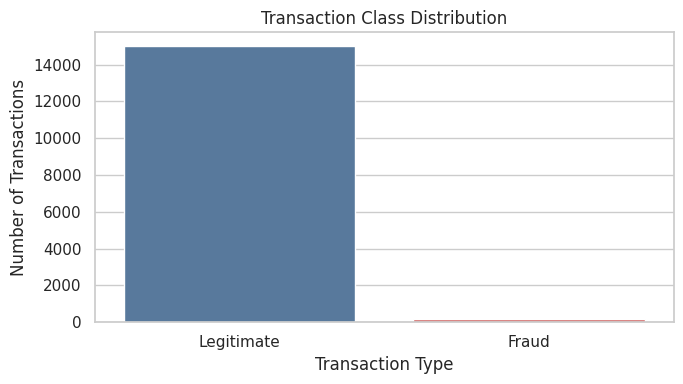

In [4]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=mini_df,
    x="Class",
    hue="Class",
    palette=["#4C78A8", "#E45756"],
    legend=False
)

plt.title("Transaction Class Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])

plt.tight_layout()
plt.show()

In [6]:
X = mini_df.drop(columns=["Class"])
y = mini_df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 12120
Testing samples: 3030

Training class distribution:
Class
0    12000
1      120
Name: count, dtype: int64

Testing class distribution:
Class
0    3000
1      30
Name: count, dtype: int64


In [7]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!


In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "Average Precision": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Precision,Recall,F1-score,Average Precision
0,Logistic Regression,0.3068,0.9,0.4576,0.8874
1,Random Forest,1.0000,0.8,0.8889,0.8963


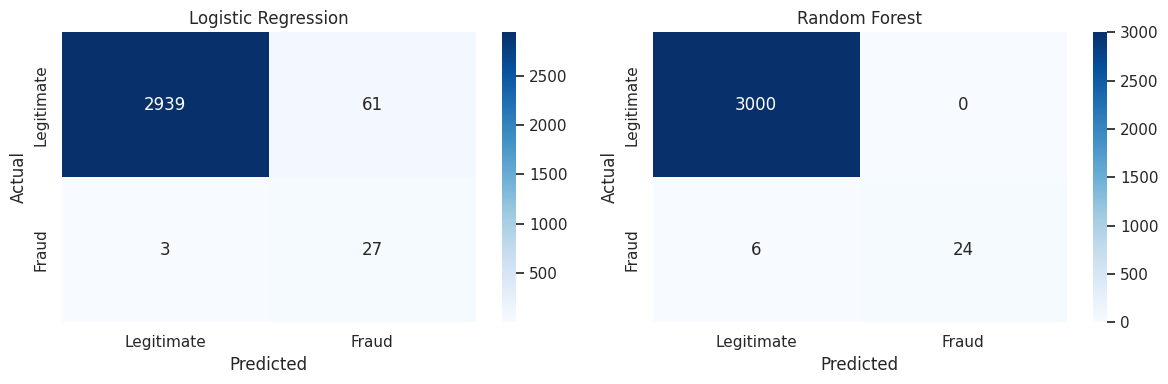

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

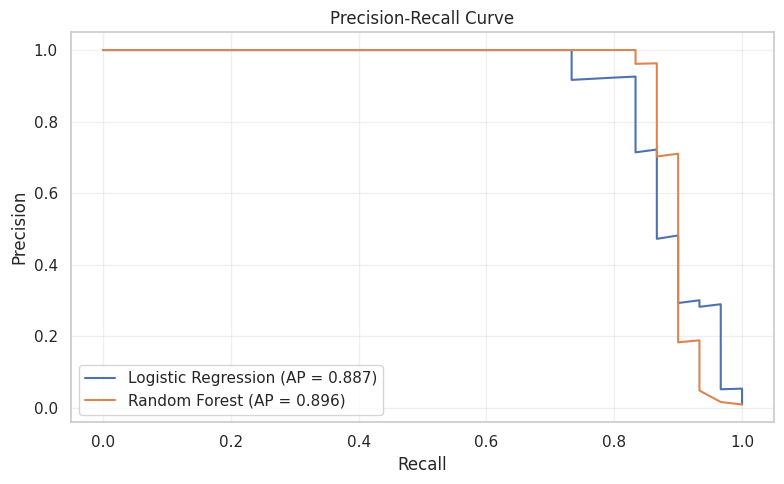

In [11]:
from sklearn.metrics import precision_recall_curve
plt.figure(figsize=(8, 5))

for name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test, y_prob
    )

    ap = average_precision_score(y_test, y_prob)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
best_model_name = results_df.sort_values(
    by="Average Precision",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

print("=" * 45)
print("FRAUDGUARD — FINAL RESULTS")
print("=" * 45)

print(f"\nBest Model: {best_model_name}")

best_results = results_df[
    results_df["Model"] == best_model_name
].iloc[0]

print(f"Precision: {best_results['Precision']:.4f}")
print(f"Recall: {best_results['Recall']:.4f}")
print(f"F1-score: {best_results['F1-score']:.4f}")
print(f"Average Precision: {best_results['Average Precision']:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_model.predict(X_test),
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

FRAUDGUARD — FINAL RESULTS

Best Model: Random Forest
Precision: 1.0000
Recall: 0.8000
F1-score: 0.8889
Average Precision: 0.8963

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      3000
       Fraud       1.00      0.80      0.89        30

    accuracy                           1.00      3030
   macro avg       1.00      0.90      0.94      3030
weighted avg       1.00      1.00      1.00      3030



## Conclusion

FraudGuard demonstrates a compact machine learning workflow
for credit card fraud detection.

### Key Achievements
- Explored imbalanced transaction data.
- Prepared stratified training and testing datasets.
- Trained Logistic Regression and Random Forest classifiers.
- Evaluated models using Precision, Recall, F1-score,
  and Average Precision.
- Visualized classification errors using confusion matrices.
- Compared model performance using Precision-Recall curves.

### Limitations
- The dataset is an intentionally sampled subset of the
  original credit card transaction dataset.
- Model performance may not represent real-world fraud rates.
- Further validation is required before practical deployment.

### Future Improvements
- Cross-validation and hyperparameter tuning.
- Decision threshold optimization.
- Testing on the original transaction distribution.